# Netflix Content Popularity Analysis
**Challenge 1: Analysis of what Makes Content Popular on Netflix?**

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


In [45]:
import os
print("Current folder:", os.getcwd())
print("\nContents of current folder:")
print(os.listdir())
print("\nContents of parent folder:")
print(os.listdir(".."))

Current folder: c:\Users\User\Downloads\MICHAEL-TALUKDER\notebooks

Contents of current folder:
['netflix_popularity_analysis.ipynb']

Contents of parent folder:
['.git', '.vscode', 'data', 'KANBAN.md', 'Main', 'main.py', 'notebooks', 'README.md', 'Sprint Goal']


In [46]:
movies = pd.read_csv("../data/netflix_movies_100.csv")
users = pd.read_csv("../data/users.csv")
history = pd.read_csv("../data/watch_history.csv")

print("Movies shape:", movies.shape)
print("Users shape:", users.shape)
print("History shape:", history.shape)

Movies shape: (100, 4)
Users shape: (80, 2)
History shape: (1176, 4)


Checking for Missing Values

In [47]:
print("=== MOVIES ===")
print(movies.head())
print("\nData types:")
print(movies.dtypes)
print("\nMissing values:")
print(movies.isnull().sum())

print("\n=== USERS ===")
print(users.head())
print("\nMissing values:")
print(users.isnull().sum())

print("\n=== WATCH HISTORY ===")
print(history.head())
print("\nMissing values:")
print(history.isnull().sum())

=== MOVIES ===
   movie_id                     title   genre  release_year
0         1  The Shawshank Redemption   Drama          1994
1         2              Pulp Fiction   Crime          1994
2         3                The Matrix  Sci-Fi          1999
3         4                Fight Club   Drama          1999
4         5              Forrest Gump   Drama          1994

Data types:
movie_id        int64
title             str
genre             str
release_year    int64
dtype: object

Missing values:
movie_id        0
title           0
genre           0
release_year    0
dtype: int64

=== USERS ===
   user_id             name
0      101    Jessica Gates
1      102    Grace Stewart
2      103   Patricia Smith
3      104      Satya Allen
4      105  Nicholas Clarke

Missing values:
user_id    0
name       0
dtype: int64

=== WATCH HISTORY ===
   history_id  user_id  movie_id  rating
0           1      101         1       3
1           2      101        98       5
2           3      101 

Checking for Duplicates

In [48]:
print("=== DUPLICATES ===")
print("Movies duplicates:", movies.duplicated().sum())
print("Users duplicates:", users.duplicated().sum())
print("History duplicates:", history.duplicated().sum())

=== DUPLICATES ===
Movies duplicates: 0
Users duplicates: 0
History duplicates: 0


Check for incorrect or unexpected categories

In [49]:
print("=== UNIQUE GENRES ===")
print(movies["genre"].unique())

print("\n=== UNIQUE RATINGS ===")
print(sorted(history["rating"].unique()))

print("\n=== RELEASE YEAR RANGE ===")
print(movies["release_year"].min(), "-", movies["release_year"].max())

=== UNIQUE GENRES ===
<StringArray>
[    'Drama',     'Crime',    'Sci-Fi',    'Action',   'Fantasy',  'Thriller',
       'War', 'Adventure',   'Romance', 'Animation',    'Comedy',   'Western',
    'Horror']
Length: 13, dtype: str

=== UNIQUE RATINGS ===
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

=== RELEASE YEAR RANGE ===
1990 - 2019


Checking for outliers in ratings and watch counts

In [50]:
# Create movie_stats
movie_stats = history.groupby("movie_id").agg(
    avg_rating=("rating", "mean"),
    watch_count=("rating", "count")
).reset_index()

movie_stats = movie_stats.merge(movies, on="movie_id")
movie_stats = movie_stats.sort_values("watch_count", ascending=False)

print("movie_stats created successfully")
print(movie_stats.head())

movie_stats created successfully
    movie_id  avg_rating  watch_count               title     genre  \
2          3    3.894737           19          The Matrix    Sci-Fi   
43        44    4.157895           19            Whiplash     Drama   
46        47    3.944444           18            Parasite  Thriller   
20        21    3.722222           18  The Usual Suspects     Crime   
79        80    3.111111           18        Pretty Woman   Romance   

    release_year  
2           1999  
43          2014  
46          2019  
20          1995  
79          1990  


In [51]:
print("=== RATING SUMMARY ===")
print(history["rating"].describe())

print("\n=== WATCH COUNT SUMMARY ===")
print(movie_stats["watch_count"].describe())

print("\n=== AVERAGE RATING SUMMARY ===")
print(movie_stats["avg_rating"].describe())

=== RATING SUMMARY ===
count    1176.000000
mean        3.786565
std         1.108354
min         1.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         5.000000
Name: rating, dtype: float64

=== WATCH COUNT SUMMARY ===
count    100.000000
mean      11.760000
std        3.333697
min        5.000000
25%        9.000000
50%       11.000000
75%       14.000000
max       19.000000
Name: watch_count, dtype: float64

=== AVERAGE RATING SUMMARY ===
count    100.000000
mean       3.795358
std        0.348642
min        2.928571
25%        3.551282
50%        3.832168
75%        4.000000
max        4.500000
Name: avg_rating, dtype: float64


Visual check for outliers

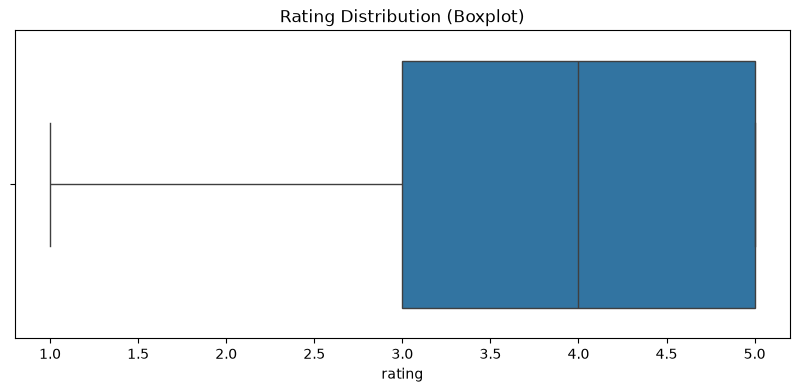

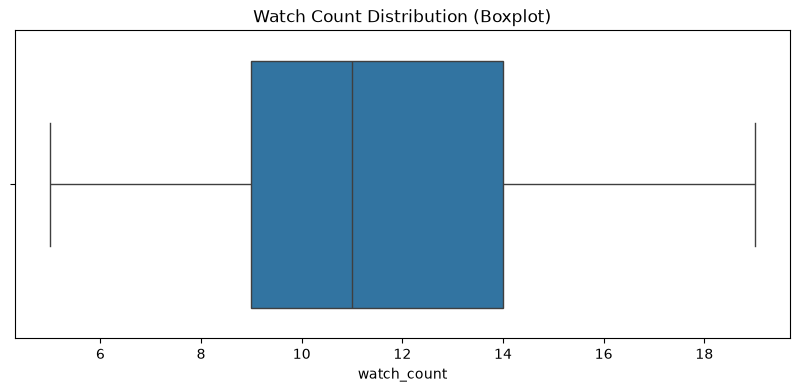

In [52]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=history["rating"])
plt.title("Rating Distribution (Boxplot)")
plt.show()

plt.figure(figsize=(10, 4))
sns.boxplot(x=movie_stats["watch_count"])
plt.title("Watch Count Distribution (Boxplot)")
plt.show()

## Data Quality Checks
- No duplicate rows were found in any dataset.
- Genres and ratings are within expected ranges.
- No extreme outliers that require removal.

In [53]:
print("=== GENRE COUNTS ===")
print(movies["genre"].value_counts())

print("\n=== RELEASE YEAR RANGE ===")
print(movies["release_year"].min(), "-", movies["release_year"].max())

print("\n=== RATING DISTRIBUTION ===")
print(history["rating"].value_counts().sort_index())

=== GENRE COUNTS ===
genre
Drama        20
Action       15
Crime        12
Animation    12
Comedy        8
Sci-Fi        7
Thriller      7
Horror        5
Fantasy       4
Romance       4
War           3
Western       2
Adventure     1
Name: count, dtype: int64

=== RELEASE YEAR RANGE ===
1990 - 2019

=== RATING DISTRIBUTION ===
rating
1     46
2    125
3    223
4    422
5    360
Name: count, dtype: int64


In [54]:
# Average rating and number of watches per movie
movie_stats = history.groupby("movie_id").agg(
    avg_rating=("rating", "mean"),
    watch_count=("rating", "count")
).reset_index()

# Merge with movie details
movie_stats = movie_stats.merge(movies, on="movie_id")

# Sort by watch count (most popular first)
movie_stats = movie_stats.sort_values("watch_count", ascending=False)

print(movie_stats.head(10))

    movie_id  avg_rating  watch_count                   title      genre  \
2          3    3.894737           19              The Matrix     Sci-Fi   
43        44    4.157895           19                Whiplash      Drama   
46        47    3.944444           18                Parasite   Thriller   
20        21    3.722222           18      The Usual Suspects      Crime   
79        80    3.111111           18            Pretty Woman    Romance   
76        77    3.944444           18                 Aladdin  Animation   
74        75    4.000000           17           The Lion King  Animation   
37        38    3.588235           17   The Dark Knight Rises     Action   
28        29    3.941176           17                    Heat      Crime   
33        34    3.764706           17  No Country for Old Men      Crime   

    release_year  
2           1999  
43          2014  
46          2019  
20          1995  
79          1990  
76          1992  
74          1994  
37         

In [55]:
#to explore genre popularity:
genre_stats = movie_stats.groupby("genre").agg(
    avg_rating=("avg_rating", "mean"),
    total_watches=("watch_count", "sum"),
    movie_count=("movie_id", "count")
).sort_values("total_watches", ascending=False)

print(genre_stats)

           avg_rating  total_watches  movie_count
genre                                            
Drama        3.823289            211           20
Action       3.738976            200           15
Crime        3.550160            147           12
Animation    3.870317            142           12
Comedy       3.965693             97            8
Thriller     4.070862             84            7
Sci-Fi       3.669028             81            7
Horror       3.835152             52            5
Romance      3.795527             51            4
Fantasy      3.803030             48            4
Western      3.885417             28            2
War          3.712821             26            3
Adventure    3.555556              9            1


In [56]:
#year trends
year_stats = movie_stats.groupby("release_year").agg(
    avg_rating=("avg_rating", "mean"),
    total_watches=("watch_count", "sum")
).reset_index()

print(year_stats.head(10))

   release_year  avg_rating  total_watches
0          1990    3.513228             45
1          1991    3.839566             38
2          1992    3.925926             38
3          1993    3.966667             38
4          1994    3.713333             65
5          1995    3.768528             57
6          1996    3.447811             26
7          1997    3.669697             28
8          1998    3.982143             41
9          1999    3.842991            100


### Visualization 1 - Histogram: Total Watches by Genre
This chart shows which genres are watched the most

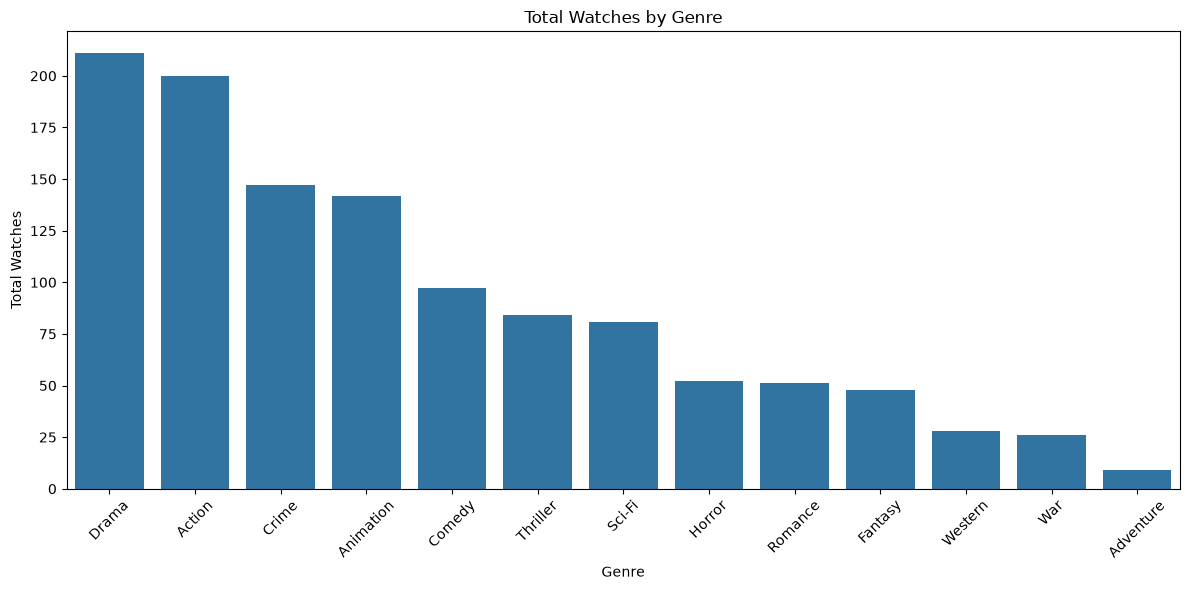

In [57]:
plt.figure(figsize=(12, 6))
sns.barplot(data=genre_stats.reset_index(), x="genre", y="total_watches")
plt.title("Total Watches by Genre")
plt.xlabel("Genre")
plt.ylabel("Total Watches")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Visualization 2: Average Rating by Genre
This chart shows the average user rating for each genre. It helps identify which genres are rated most highly by viewers, independent of how many times they were watched.

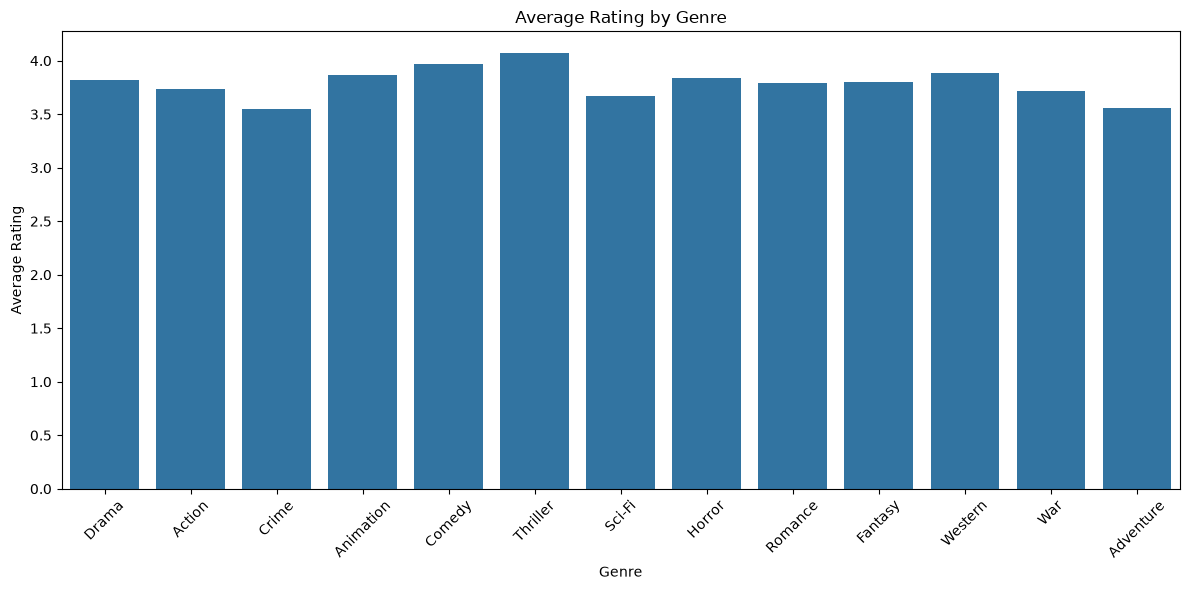

In [58]:
plt.figure(figsize=(12, 6))
sns.barplot(data=genre_stats.reset_index(), x="genre", y="avg_rating")
plt.title("Average Rating by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Visualization 3: Top 10 Most Watched Movies
This chart displays the ten movies with the highest number of watches. It highlights the most popular individual titles in the dataset.

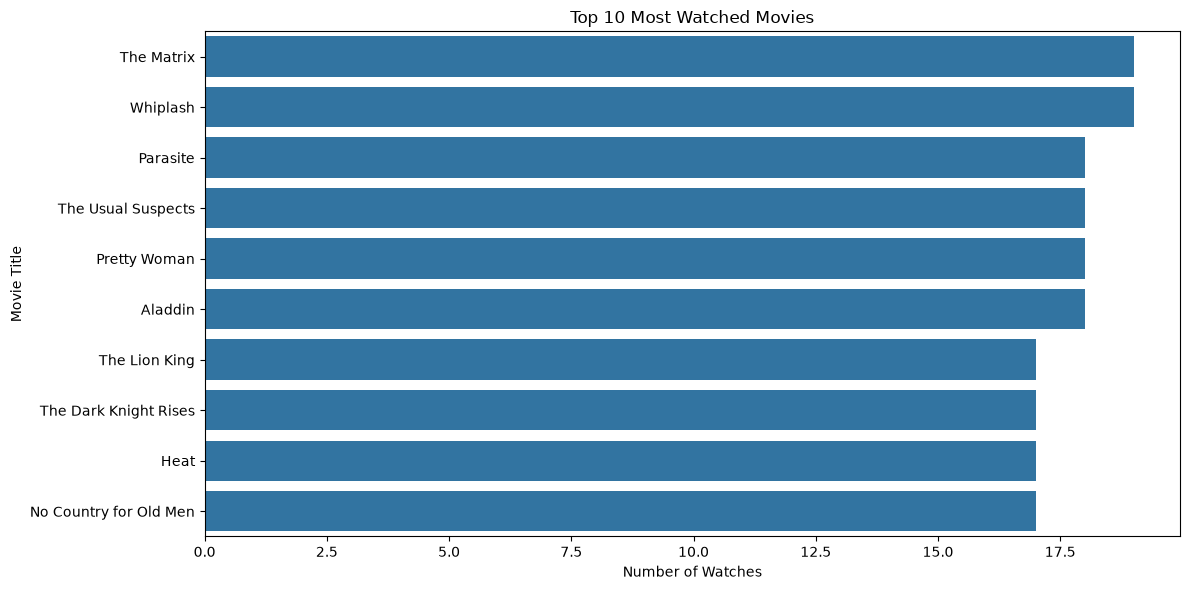

In [59]:
top10 = movie_stats.head(10)
plt.figure(figsize=(12, 6))
sns.barplot(data=top10, x="watch_count", y="title")
plt.title("Top 10 Most Watched Movies")
plt.xlabel("Number of Watches")
plt.ylabel("Movie Title")
plt.tight_layout()
plt.show()

## Business Insights

1. **Drama and Action are the most watched genres.**
2. **Higher watch counts do not always mean higher average ratings.** - some popular titles have moderate scores.
3. **Content from the 1990s and 2010s appears frequently among the top-watched titles.**

## Conclusions

Based on the analysis, the most popular Netflix content tends to be in the Drama and Action genres. 
Recommendations for Netflix include investing more in these genres while monitoring ratings to maintain quality.